In [47]:
import torch
import numpy as NP
import matplotlib.pyplot as plt
from torch import nn


dataset = torch.load('./training_set/train-dev_dataset_with_labels.pt')

inputs = dataset[:,:,:-1]
labels = dataset[:, :, -1]

In [48]:
print("Dataset:", dataset.shape)
print("Inputs:", inputs.shape)
print("Labels:", labels.shape)

Dataset: torch.Size([2473, 1, 769])
Inputs: torch.Size([2473, 1, 768])
Labels: torch.Size([2473, 1])


In [49]:
X = inputs.reshape(-1, inputs.shape[-1])
y = labels.reshape(-1).long()

print("Samples:", len(X))
print("Features:", X.shape[1])

print("Classes:", torch.unique(y, return_counts=True))
print("All finite:", torch.isfinite(X).all().item())

Samples: 2473
Features: 768
Classes: (tensor([0, 1, 2, 3, 4, 5, 6]), tensor([319, 232, 397, 400, 394, 364, 367]))
All finite: True


In [50]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [51]:
print("Min:", X.min().item())
print("Max:", X.max().item())
print("Mean:", X.mean().item())
print("Std:", X.std().item())

Min: -0.9777563810348511
Max: 0.9692857265472412
Mean: -0.0010174948256462812
Std: 0.6051807999610901


In [52]:
means = X.mean(dim=0)
stds = X.std(dim=0)

print(means[:10])
print(stds[:10])

tensor([-0.0398,  0.0784, -0.1308,  0.0357, -0.1155, -0.0049,  0.1367, -0.0463,
         0.0374,  0.1666])
tensor([0.4638, 0.5756, 0.5525, 0.5490, 0.5287, 0.5285, 0.5664, 0.5525, 0.5400,
        0.5942])


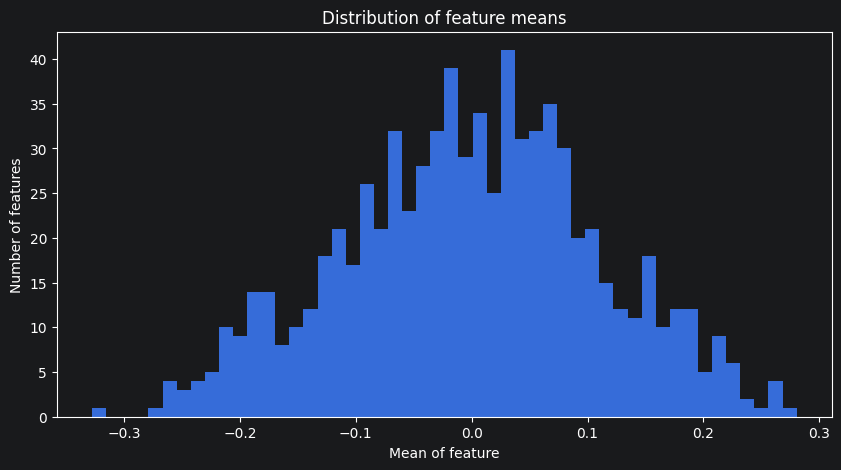

In [53]:
feature_means = X.mean(dim=0).cpu().numpy()

plt.figure(figsize=(10, 5))
plt.hist(feature_means, bins=50)

plt.xlabel("Mean of feature")
plt.ylabel("Number of features")
plt.title("Distribution of feature means")
plt.show()

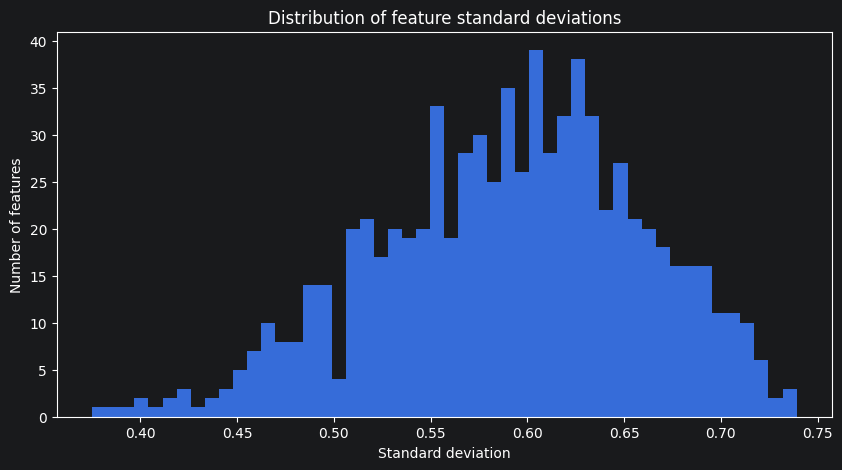

In [54]:
feature_stds = X.std(dim=0).cpu().numpy()

plt.figure(figsize=(10, 5))
plt.hist(feature_stds, bins=50)

plt.xlabel("Standard deviation")
plt.ylabel("Number of features")
plt.title("Distribution of feature standard deviations")
plt.show()

In [55]:
import torch
import random

class SevenWayClassifier():
  def __init__(self, ):
    base_clf = torch.nn.Linear(in_features=768, out_features=5, bias=True)
    base_clf.load_state_dict(torch.load("training_set/base_classifier.pth"))
    self.base_clf = base_clf

  def base_classification(self, input_vector):

    with torch.no_grad():
      logits = self.base_clf(input_vector)
      preds = torch.softmax(logits, 1)
      predicted_class = preds.argmax(dim=1).numpy()[0]

    return predicted_class

  def __call__(self, input_vector):

    random_class = random.choice([0,1,2,3,4,5,6])
    if random_class in [5,6]:
      predicted_class = random_class
    else:
      predicted_class = self.base_classification(input_vector)

    return predicted_class

clf = SevenWayClassifier()

In [56]:
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

model = KNeighborsClassifier(
    n_neighbors=3,
    weights="distance"
)

model.fit(X_train_scaled, y_train)

X_test = np.array([[178, 75]])
X_val_scaled = scaler.transform(X_val)

val_predictions = model.predict(X_val_scaled)

from sklearn.metrics import f1_score
print("F1-score:", f1_score(y_val, val_predictions, average="macro"))

F1-score: 0.8591560595580346


In [57]:
class SmartSevenWayClassifier:
    def __init__(self):
        base_clf = torch.nn.Linear(in_features=768, out_features=5, bias=True)
        base_clf.load_state_dict(torch.load("training_set/base_classifier.pth"))
        self.base_clf = base_clf

    def base_classification(self, input_vector):
        with torch.no_grad():
            logits = self.base_clf(input_vector)
            preds = torch.softmax(logits, dim=1)
            predicted_class = preds.argmax(dim=1).item()

        return predicted_class

    def __call__(self, input_vector):
        scaled_vector = scaler.transform(input_vector)
        predicted = int(model.predict(scaled_vector)[0])

        if predicted in [5, 6]:
            predicted_class = predicted
        else:
            predicted_class = self.base_classification(input_vector)

        return predicted_class

        # random_class = random.choice([0, 1, 2, 3, 4, 5, 6])
        #
        # if random_class in [5, 6]:
        #     predicted_class = random_class
        # else:
        #     predicted_class = self.base_classification(input_vector)
        #
        # return predicted_class

clf = SmartSevenWayClassifier()

In [58]:
from sklearn.metrics import f1_score

def compute_f1(labels, predictions):
  return f1_score(labels, predictions, average='macro')

In [59]:
from tqdm import tqdm

def inference(clf, input_vectors):
  predictions = []
  for sample in tqdm(input_vectors):
    predictions.append(clf(sample))
  return predictions

In [60]:
predictions = inference(clf, X_val)

f1 = compute_f1(y_val, predictions)

print("Validation Macro F1:", f1)

  0%|          | 0/495 [00:00<?, ?it/s]


ValueError: Expected 2D array, got 1D array instead:
array=[-0.15710759  0.84800828 -0.7124908   0.03930289  0.36436951 -0.72500396
  0.06981479 -0.76523674 -0.83936942 -0.10217684  0.55524123  0.88173735
 -0.90853232 -0.65659618  0.23423119 -0.35176146  0.0142296  -0.30197978
 -0.40376624 -0.76009864  0.37856445  0.59750068 -0.68125367  0.58560622
  0.611601    0.25052017 -0.67238843 -0.56415403  0.77626401  0.13148588
 -0.50535518 -0.41170698 -0.46463412  0.72399426  0.52735257 -0.82956421
 -0.83261508 -0.92474174 -0.74904466 -0.64087945  0.79262435  0.05000481
  0.29157963  0.55158389 -0.64532197  0.32644582  0.50934488  0.88901377
  0.45082608 -0.69175375  0.68102127 -0.62604678 -0.43534791  0.84696376
  0.40003282  0.75629437  0.68964565  0.34479135 -0.4647494   0.90466082
  0.75730121  0.23109482 -0.03933166  0.74979448  0.81767541 -0.67299366
 -0.17294092  0.78831619  0.88728619 -0.72772646 -0.22917566 -0.07497203
  0.76870918  0.1763379  -0.62409127  0.88724202 -0.80405277 -0.8

In [61]:
predictions = inference(clf, inputs)

f1 = compute_f1(labels, predictions)
print('Naive solution F1', f1)

100%|██████████| 2473/2473 [00:02<00:00, 898.05it/s] 

Naive solution F1 0.9626585555377469


In [62]:
# The leaderboard may or may not work... If it doesn't forgive us. We will try to get it running.

import pandas as pd
import numpy as np

def submission_to_csv(pred: np.ndarray, output_fpath: str = "submission.csv"):
    pred = np.array(pred).flatten()
    data_size = pred.size
    df = pd.DataFrame({
        "ID": np.arange(data_size),
        "class": pred
    })

    df.to_csv(output_fpath, index=False)

eval_inputs = torch.load('./Solution/validation_set/eval_dataset.pt')

eval_predictions = inference(clf, eval_inputs)

submission_to_csv(eval_predictions)

100%|██████████| 200/200 [00:00<00:00, 944.20it/s]


In [63]:
# DO NOT CHANGE THIS CELL

# this download link will not work until two hours before the end of the competition
test_inputs = torch.load('Solution/test_set/test_dataset.pt')

split='test'

test_predictions = inference(clf, test_inputs)

with open('{}_predictions.txt'.format("Team Name"), 'w') as outfile:
  outfile.write('\n'.join([str(p) for p in test_predictions]))

100%|██████████| 700/700 [00:00<00:00, 960.00it/s] 
